# CS770 Visual Quality Inspection

## Team members

- Supriya Gurung
- Jennifer Isobe
- Sydney Epke

## How to run

Install the packages listed in requirements.txt and select that
Python environment as the notebook kernel.

Place the original dataset in data/casting_512x512/, with
def_front and ok_front directly inside that folder.

Run this notebook from the repository root. Restart the kernel and
run all cells in order. The audit and split cells reproduce the
fixed split using seed 770; model-loading cells use the saved
split manifest.

This working notebook currently contains data preparation and
the logistic regression baseline. The final submission notebook
will also include both CNN configurations and final evaluation.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from PIL import Image

print("Python:", sys.version.split()[0])
print("Python location:", sys.executable)
print("PyTorch:", torch.__version__)
print("Working folder:", Path.cwd())

DATA_DIR = Path("data") / "casting_512x512"

print("\nDataset folder found:", DATA_DIR.is_dir())

for class_name in ["def_front", "ok_front"]:
    folder = DATA_DIR / class_name

    if not folder.is_dir():
        print(f"{class_name}: FOLDER NOT FOUND")
        continue

    images = [
        path for path in folder.iterdir()
        if path.is_file()
        and path.suffix.lower()
        in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    ]

    print(f"{class_name}: {len(images)} image files")

Python: 3.14.7
Python location: c:\Users\sydro\Desktop\MachineLearning\visual_quality_inspection\.venv314\Scripts\python.exe
PyTorch: 2.15.0+cpu
Working folder: c:\Users\sydro\Desktop\MachineLearning\visual_quality_inspection

Dataset folder found: True
def_front: 781 image files
ok_front: 519 image files


In [2]:
import hashlib
import pandas as pd
from PIL import Image

LABEL_MAP = {"ok_front": 0, "def_front": 1}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

records = []
unreadable = []

for class_name, label in LABEL_MAP.items():
    folder = DATA_DIR / class_name

    for path in sorted(folder.iterdir()):
        if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        relative_path = path.relative_to(DATA_DIR).as_posix()

        try:
            with Image.open(path) as image:
                image.load()
                width, height = image.size
                original_mode = image.mode

                # Compare decoded pixel content, not filenames or file metadata.
                rgb_image = image.convert("RGB")
                digest = hashlib.sha256()
                digest.update(f"{width}x{height}|RGB|".encode())
                digest.update(rgb_image.tobytes())

            records.append({
                "relative_path": relative_path,
                "class_name": class_name,
                "label": label,
                "width": width,
                "height": height,
                "original_mode": original_mode,
                "content_hash": digest.hexdigest(),
            })

        except Exception as error:
            unreadable.append({
                "relative_path": relative_path,
                "reason": str(error),
            })

audit_df = pd.DataFrame(records)
unreadable_df = pd.DataFrame(
    unreadable, columns=["relative_path", "reason"]
)

assert not audit_df.empty, "No readable images found. Check DATA_DIR."

duplicate_rows = audit_df[
    audit_df.duplicated("content_hash", keep=False)
].sort_values(["content_hash", "relative_path"])

label_counts = audit_df.groupby("content_hash")["label"].nunique()
conflicting_hashes = label_counts[label_counts > 1].index

print("Readable images:", len(audit_df))
print("Unreadable images:", len(unreadable_df))

print("\nImage dimensions:")
print(
    audit_df.groupby(["width", "height"])
    .size()
    .rename("count")
    .to_string()
)

print("\nReadable images by class:")
print(audit_df["class_name"].value_counts().to_string())

print("\nDuplicate content groups:", duplicate_rows["content_hash"].nunique())
print("Images in duplicate groups:", len(duplicate_rows))
print("Groups with conflicting labels:", len(conflicting_hashes))

if not unreadable_df.empty:
    display(unreadable_df)

if not duplicate_rows.empty:
    display(
        duplicate_rows[
            ["relative_path", "label", "content_hash"]
        ]
    )

Readable images: 1300
Unreadable images: 0

Image dimensions:
width  height
512    512       1300

Readable images by class:
class_name
def_front    781
ok_front     519

Duplicate content groups: 0
Images in duplicate groups: 0
Groups with conflicting labels: 0


## Data audit

The original casting_512x512 collection contains about 1,300 images: 781 are defective and 519 are acceptable. All images were readable and had the dimensions of 512 x 512 pixels. Comparing these decoded RGB pixel content found no exact duplicate iamges or conflicting-label duplicates. No images were excluded based on these checks.

Labels: acceptable = 0; defective = 1.

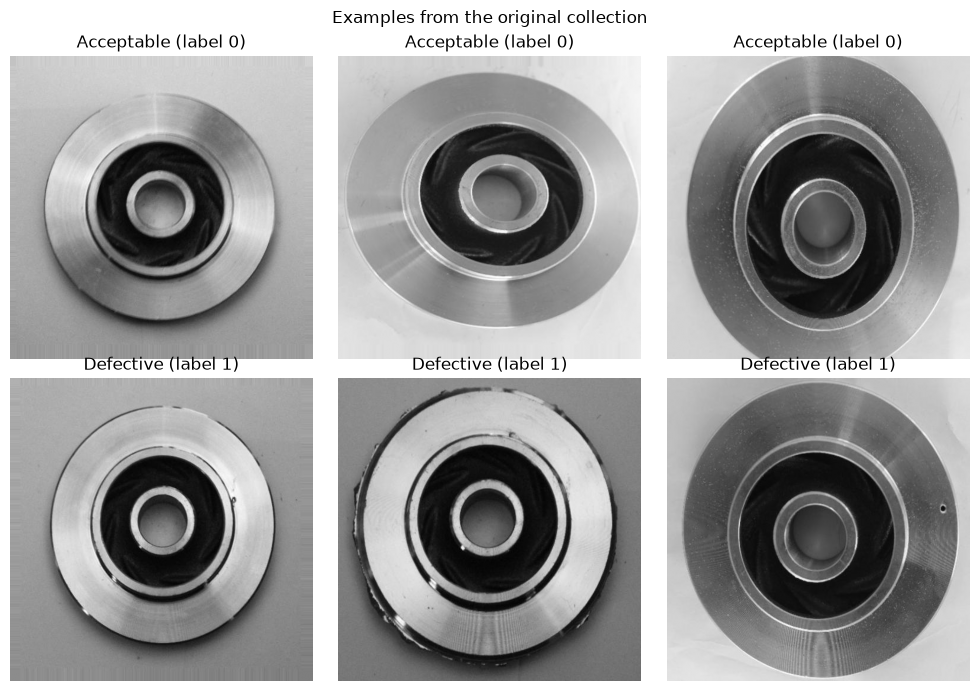

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for row_index, class_name in enumerate(["ok_front", "def_front"]):
    samples = audit_df[
        audit_df["class_name"] == class_name
    ].sample(n=3, random_state=770)

    for ax, (_, row) in zip(axes[row_index], samples.iterrows()):
        with Image.open(DATA_DIR / row["relative_path"]) as image:
            ax.imshow(image.convert("L"), cmap="gray")

        label_name = "Defective" if row["label"] == 1 else "Acceptable"
        ax.set_title(f"{label_name} (label {row['label']})")
        ax.axis("off")

plt.suptitle("Examples from the original collection")
plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

SEED = 770

# Every audited image passed our checks.
# Sort first so the starting order is reproducible.
clean_df = audit_df.sort_values("relative_path").reset_index(drop=True)

# Reserve 30% for validation + test.
train_df, remaining_df = train_test_split(
    clean_df,
    test_size=0.30,
    stratify=clean_df["label"],
    random_state=SEED,
)

# Divide that reserved portion equally.
val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df["label"],
    random_state=SEED,
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

split_manifest = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True,
).sort_values(["split", "relative_path"]).reset_index(drop=True)

# Verify every image appears exactly once.
assert len(split_manifest) == len(clean_df)
assert split_manifest["relative_path"].is_unique
assert split_manifest["content_hash"].is_unique

split_counts = pd.crosstab(
    split_manifest["split"],
    split_manifest["label"],
).reindex(["train", "validation", "test"])

split_counts = split_counts.rename(
    columns={0: "Acceptable (0)", 1: "Defective (1)"}
)
split_counts["Total"] = split_counts.sum(axis=1)

display(split_counts)

label,Acceptable (0),Defective (1),Total
split,,,
train,363,547,910
validation,78,117,195
test,78,117,195


In [5]:
SPLIT_DIR = Path("splits")
SPLIT_DIR.mkdir(exist_ok=True)

audit_df.to_csv(SPLIT_DIR / "image_audit.csv", index=False)
unreadable_df.to_csv(SPLIT_DIR / "unreadable_images.csv", index=False)

split_manifest[
    ["relative_path", "label", "split", "content_hash"]
].to_csv(SPLIT_DIR / "split_manifest.csv", index=False)

# Print the complete filename lists into the notebook output,
# as required for reproducibility.
for split_name in ["train", "validation", "test"]:
    rows = split_manifest[
        split_manifest["split"] == split_name
    ]

    print(f"\n{split_name.upper()}: {len(rows)} images")
    print(rows[["relative_path", "label"]].to_string(index=False))

print("\nSaved audit and split CSV files in:", SPLIT_DIR.resolve())


TRAIN: 910 images
                 relative_path  label
   def_front/cast_def_0_0.jpeg      1
def_front/cast_def_0_1015.jpeg      1
 def_front/cast_def_0_102.jpeg      1
def_front/cast_def_0_1053.jpeg      1
def_front/cast_def_0_1055.jpeg      1
def_front/cast_def_0_1087.jpeg      1
def_front/cast_def_0_1091.jpeg      1
def_front/cast_def_0_1112.jpeg      1
def_front/cast_def_0_1115.jpeg      1
def_front/cast_def_0_1123.jpeg      1
def_front/cast_def_0_1137.jpeg      1
def_front/cast_def_0_1139.jpeg      1
def_front/cast_def_0_1145.jpeg      1
def_front/cast_def_0_1147.jpeg      1
def_front/cast_def_0_1155.jpeg      1
def_front/cast_def_0_1157.jpeg      1
def_front/cast_def_0_1187.jpeg      1
def_front/cast_def_0_1188.jpeg      1
def_front/cast_def_0_1225.jpeg      1
def_front/cast_def_0_1226.jpeg      1
def_front/cast_def_0_1257.jpeg      1
def_front/cast_def_0_1261.jpeg      1
 def_front/cast_def_0_127.jpeg      1
def_front/cast_def_0_1283.jpeg      1
def_front/cast_def_0_1286.jpeg 

## Image preprocessing

Images are converted to grayscale, resized to 64 × 64 using bilinear
resampling, and scaled to [0, 1] by dividing pixel values by 255.
Both logistic regression and the CNN use this same preprocessing.

No learned normalization or data augmentation is used.
The test images remain unused until final model selection.

In [6]:
import numpy as np

IMAGE_SIZE = (64, 64)

# Load the shared split list instead of creating new splits.
manifest = pd.read_csv(Path("splits") / "split_manifest.csv")

def load_image_split(split_name):
    rows = (
        manifest[manifest["split"] == split_name]
        .sort_values("relative_path")
        .reset_index(drop=True)
    )

    images = []

    for relative_path in rows["relative_path"]:
        with Image.open(DATA_DIR / relative_path) as image:
            image = image.convert("L")
            image = image.resize(
                IMAGE_SIZE,
                resample=Image.Resampling.BILINEAR,
            )
            pixels = np.asarray(image, dtype=np.float32) / 255.0
            images.append(pixels)

    X = np.stack(images)
    y = rows["label"].to_numpy(dtype=np.int64)

    return X, y, rows

X_train_images, y_train, train_rows = load_image_split("train")
X_val_images, y_val, val_rows = load_image_split("validation")

# Flatten the same prepared images for logistic regression.
X_train_flat = X_train_images.reshape(len(X_train_images), -1)
X_val_flat = X_val_images.reshape(len(X_val_images), -1)

assert np.isfinite(X_train_images).all()
assert np.isfinite(X_val_images).all()
assert 0 <= X_train_images.min() <= X_train_images.max() <= 1
assert 0 <= X_val_images.min() <= X_val_images.max() <= 1

print("Training images:", X_train_images.shape)
print("Validation images:", X_val_images.shape)
print("Flattened training inputs:", X_train_flat.shape)
print("Flattened validation inputs:", X_val_flat.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Training pixel range:",
      X_train_images.min(), "to", X_train_images.max())
print("Preprocessing complete!")

Training images: (910, 64, 64)
Validation images: (195, 64, 64)
Flattened training inputs: (910, 4096)
Flattened validation inputs: (195, 4096)
Training labels: (910,)
Validation labels: (195,)
Training pixel range: 0.023529412 to 1.0
Preprocessing complete!


## Logistic regression baseline

The baseline uses grayscale 64 × 64 images, scaled to [0, 1] and
flattened into 4,096 features per image.

Settings: logistic regression with the lbfgs solver, C = 1.0,
maximum 2,000 iterations, tolerance = 0.0001, and random seed 770.
No class weighting is applied.

An image is classified as defective when its predicted defect
probability is at least 0.5. Performance is measured on the
validation set; the test set remains unused.

In [7]:
import time
import warnings

from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)

baseline_model = LogisticRegression(
    solver="lbfgs",
    C=1.0,
    max_iter=2000,
    tol=1e-4,
    random_state=770,
)

# Record fitting time and any warnings.
with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always")

    start_time = time.perf_counter()
    baseline_model.fit(X_train_flat, y_train)
    baseline_training_seconds = time.perf_counter() - start_time

baseline_warning_messages = [
    str(warning.message) for warning in caught_warnings
]

convergence_issue = any(
    issubclass(warning.category, ConvergenceWarning)
    for warning in caught_warnings
)

# Locate the probability column for defective = 1.
defect_column = list(baseline_model.classes_).index(1)

baseline_val_probabilities = baseline_model.predict_proba(
    X_val_flat
)[:, defect_column]

# Keep the required decision threshold fixed.
baseline_val_predictions = (
    baseline_val_probabilities >= 0.5
).astype(np.int64)

baseline_results = {
    "Configuration": "Logistic regression",
    "Precision": precision_score(
        y_val, baseline_val_predictions,
        pos_label=1, zero_division=0,
    ),
    "Recall": recall_score(
        y_val, baseline_val_predictions,
        pos_label=1, zero_division=0,
    ),
    "F1": f1_score(
        y_val, baseline_val_predictions,
        pos_label=1, zero_division=0,
    ),
    "Accuracy": accuracy_score(
        y_val, baseline_val_predictions,
    ),
    "Training time (seconds)": baseline_training_seconds,
}

display(pd.DataFrame([baseline_results]).round(4))

print("Solver iterations:", int(baseline_model.n_iter_[0]))
print("Convergence warning:", convergence_issue)

if baseline_warning_messages:
    print("\nWarnings recorded:")
    for message in baseline_warning_messages:
        print("-", message)
else:
    print("No warnings recorded.")

print("\nBaseline complete. Test set has not been evaluated.")

,Configuration,Precision,Recall,F1,Accuracy,Training time (seconds)
0,Logistic regression,0.8609,0.8462,0.8534,0.8256,1.7001


Solver iterations: 512
Convergence warning: False
No warnings recorded.

Baseline complete. Test set has not been evaluated.


## CNN controlled comparison

We use the frozen training and validation arrays prepared above. No test
preprocessing or test prediction is performed in this section.

The first CNN has no dropout. The second CNN changes only the dropout
probability from 0.0 to 0.25; preprocessing, split, architecture, seed,
batch size, optimizer, learning rate, loss, and training epochs remain fixed.

We expect dropout to reduce overfitting by limiting dependence on particular
features. It may improve validation F1, but it could also reduce recall if
regularization is too strong.

In [8]:
import random
import time

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)

SEED = 770
CNN_EPOCHS = 15
CNN_BATCH_SIZE = 32
CNN_LEARNING_RATE = 1e-3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch:", torch.__version__)
print("CNN epochs:", CNN_EPOCHS)
print("Batch size:", CNN_BATCH_SIZE)
print("Learning rate:", CNN_LEARNING_RATE)

X_train_tensor = torch.from_numpy(np.array(X_train_images, copy=True)).unsqueeze(1)
X_val_tensor = torch.from_numpy(np.array(X_val_images, copy=True)).unsqueeze(1)
y_train_tensor = torch.from_numpy(np.array(y_train, copy=True)).float()
y_val_tensor = torch.from_numpy(np.array(y_val, copy=True)).float()


class SmallCastingCNN(nn.Module):
    def __init__(self, dropout_probability=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 256),
            nn.ReLU(),
            nn.Dropout(p=dropout_probability),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_cnn(dropout_probability, configuration_name):
    set_seed(SEED)

    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

    model = SmallCastingCNN(dropout_probability).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=CNN_LEARNING_RATE,
    )

    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        TensorDataset(X_train_tensor, y_train_tensor),
        batch_size=CNN_BATCH_SIZE,
        shuffle=True,
        generator=generator,
    )

    train_losses = []
    val_losses = []

    start_time = time.perf_counter()
    for epoch in range(1, CNN_EPOCHS + 1):
        model.train()
        batch_train_losses = []

        for batch_images, batch_labels in train_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            optimizer.zero_grad()
            logits = model(batch_images)
            loss = criterion(logits, batch_labels)
            loss.backward()
            optimizer.step()
            batch_train_losses.append(loss.item())

        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_tensor.to(device))
            val_loss = criterion(
                val_logits,
                y_val_tensor.to(device),
            ).item()

        epoch_train_loss = float(np.mean(batch_train_losses))
        train_losses.append(epoch_train_loss)
        val_losses.append(val_loss)
        print(
            f"{configuration_name} epoch {epoch:02d}/{CNN_EPOCHS}: "
            f"train loss={epoch_train_loss:.4f}, val loss={val_loss:.4f}"
        )

    training_seconds = time.perf_counter() - start_time

    model.eval()
    with torch.no_grad():
        val_probabilities = torch.sigmoid(
            model(X_val_tensor.to(device))
        ).detach().cpu().numpy()

    val_predictions = (val_probabilities >= 0.5).astype(np.int64)

    metrics = {
        "Configuration": configuration_name,
        "Precision": precision_score(
            y_val, val_predictions, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, pos_label=1, zero_division=0
        ),
        "F1": f1_score(
            y_val, val_predictions, pos_label=1, zero_division=0
        ),
        "Accuracy": accuracy_score(y_val, val_predictions),
        "Training time (seconds)": training_seconds,
    }

    return model, metrics, train_losses, val_losses


cnn_a_model, cnn_a_results, cnn_a_train_loss, cnn_a_val_loss = train_cnn(
    dropout_probability=0.0,
    configuration_name="CNN A (no dropout)",
)

cnn_b_model, cnn_b_results, cnn_b_train_loss, cnn_b_val_loss = train_cnn(
    dropout_probability=0.25,
    configuration_name="CNN B (dropout 0.25)",
)


Device: cpu
PyTorch: 2.15.0+cpu
CNN epochs: 15
Batch size: 32
Learning rate: 0.001
CNN A (no dropout) epoch 01/15: train loss=0.5948, val loss=0.5236
CNN A (no dropout) epoch 02/15: train loss=0.5180, val loss=0.4627
CNN A (no dropout) epoch 03/15: train loss=0.4847, val loss=0.4563
CNN A (no dropout) epoch 04/15: train loss=0.4189, val loss=0.4303
CNN A (no dropout) epoch 05/15: train loss=0.3847, val loss=0.4158
CNN A (no dropout) epoch 06/15: train loss=0.3701, val loss=0.4410
CNN A (no dropout) epoch 07/15: train loss=0.3183, val loss=0.4159
CNN A (no dropout) epoch 08/15: train loss=0.2887, val loss=0.3824
CNN A (no dropout) epoch 09/15: train loss=0.2839, val loss=0.4121
CNN A (no dropout) epoch 10/15: train loss=0.2764, val loss=0.3583
CNN A (no dropout) epoch 11/15: train loss=0.2289, val loss=0.4707
CNN A (no dropout) epoch 12/15: train loss=0.2600, val loss=0.3422
CNN A (no dropout) epoch 13/15: train loss=0.1878, val loss=0.3637
CNN A (no dropout) epoch 14/15: train loss=0.1

### Validation comparison and training curves

The table below compares all three configurations using the fixed validation
set and 0.5 defect probability threshold. The test set remains unused.

,Configuration,Precision,Recall,F1,Accuracy,Training time (seconds)
0,Logistic regression,0.8609,0.8462,0.8534,0.8256,1.7001
1,CNN A (no dropout),0.8295,0.9145,0.8699,0.8359,24.0433
2,CNN B (dropout 0.25),0.8295,0.9145,0.8699,0.8359,24.6535


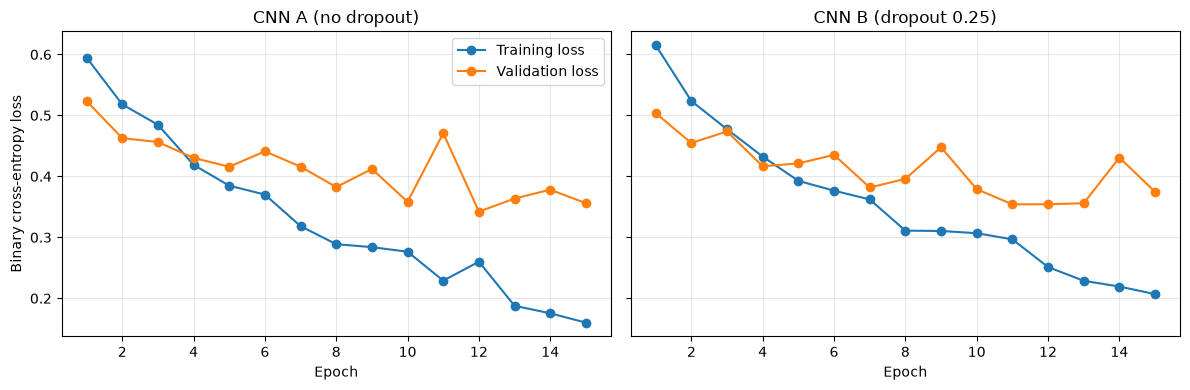

In [9]:
comparison_df = pd.DataFrame([
    baseline_results,
    cnn_a_results,
    cnn_b_results,
])

display(comparison_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

run_results = [
    ("CNN A (no dropout)", cnn_a_train_loss, cnn_a_val_loss),
    ("CNN B (dropout 0.25)", cnn_b_train_loss, cnn_b_val_loss),
]

for ax, (run_name, train_losses, val_losses) in zip(axes, run_results):
    epochs = np.arange(1, CNN_EPOCHS + 1)
    ax.plot(epochs, train_losses, marker="o", label="Training loss")
    ax.plot(epochs, val_losses, marker="o", label="Validation loss")
    ax.set_title(run_name)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].legend()
plt.tight_layout()
plt.show()


### Validation-only model selection

Select by validation defective-class F1. Break ties in favor of the simpler
model: logistic regression, then CNN A, then CNN B. No test score is inspected
before this point.

In [10]:
selection_candidates = [
    ("Logistic regression", baseline_results["F1"], "baseline"),
    ("CNN A (no dropout)", cnn_a_results["F1"], "cnn_a"),
    ("CNN B (dropout 0.25)", cnn_b_results["F1"], "cnn_b"),
]

best_f1 = max(candidate[1] for candidate in selection_candidates)
tied_candidates = [
    candidate for candidate in selection_candidates
    if np.isclose(candidate[1], best_f1, rtol=0.0, atol=1e-12)
]

selected_name, selected_f1, selected_kind = tied_candidates[0]

if selected_kind == "baseline":
    selected_model = baseline_model
elif selected_kind == "cnn_a":
    selected_model = cnn_a_model
else:
    selected_model = cnn_b_model

print("Validation defective-F1:", round(selected_f1, 4))
print("Selected configuration:", selected_name)
print("Test set: not evaluated")


Validation defective-F1: 0.8699
Selected configuration: CNN A (no dropout)
Test set: not evaluated
